<a href="https://colab.research.google.com/github/kumarVaibhav02/Sonic_signatures/blob/main/Copy_of_Untitled0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Loading the three songs :

In [ ]:
!pip install -q librosa soundfile

import numpy as np, pandas as pd, matplotlib.pyplot as plt, librosa
from scipy.ndimage import maximum_filter
from collections import defaultdict, Counter
from google.colab import files

uploaded = files.upload()

SONG_PATHS = {"song1": "song1.mp3", "song2": "song2.mp3", "song3": "song3.mp3"}
SR = 22050
N_FFT, HOP = 2048, 512

Saving song3.mp3 to song3 (1).mp3
Saving song2.mp3 to song2 (1).mp3
Saving song1.mp3 to song1 (1).mp3


TASK 1

,song,orig_sample_rate,orig_channels,orig_duration_s,new_sample_rate,new_channels,new_samples
0,song1,44100,2,194.35,22050,1,4285464
1,song2,44100,2,218.80,22050,1,4824600
2,song3,44100,2,260.99,22050,1,5754816


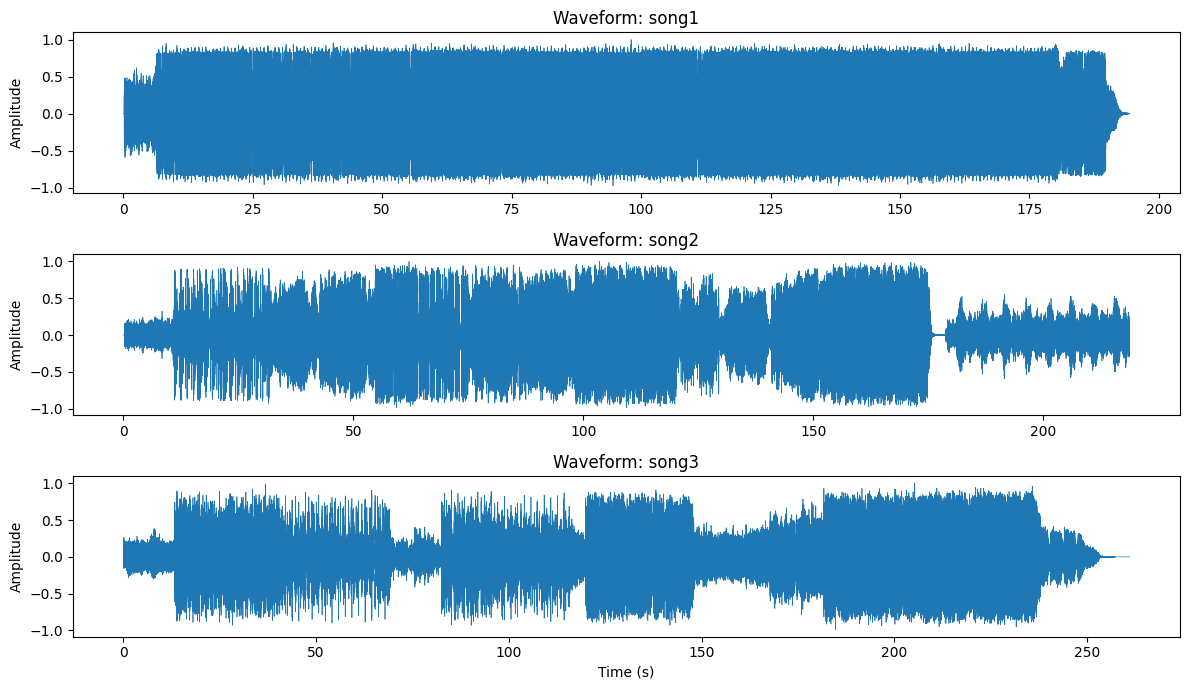

In [ ]:
def load_audio(path, sr=SR, mono=True, normalize=True):
    """Load any audio file -> mono, fixed sample rate, peak-normalised float array."""
    y, _ = librosa.load(path, sr=sr, mono=mono)
    if normalize:
        y = y / (np.max(np.abs(y)) + 1e-9)
    return y, sr

songs, rows = {}, []
for name, path in SONG_PATHS.items():

    y_raw, sr_orig = librosa.load(path, sr=None, mono=False)
    channels = 1 if y_raw.ndim == 1 else y_raw.shape[0]
    duration = y_raw.shape[-1] / sr_orig

    y, sr = load_audio(path)
    songs[name] = y
    rows.append({"song": name, "orig_sample_rate": sr_orig, "orig_channels": channels,
                 "orig_duration_s": round(duration, 2),
                 "new_sample_rate": sr, "new_channels": 1, "new_samples": len(y)})
display(pd.DataFrame(rows))

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=False)
for ax, (name, y) in zip(axes, songs.items()):
    t = np.arange(len(y)) / SR
    ax.plot(t, y, linewidth=0.5)
    ax.set_title(f"Waveform: {name}"); ax.set_ylabel("Amplitude")
axes[-1].set_xlabel("Time (s)")
plt.tight_layout(); plt.show()

TASK 2

n_fft | freq resolution (Hz) | window length (ms)
  512 |                43.07 | 23.2
 2048 |                10.77 | 92.9
 4096 |                 5.38 | 185.8


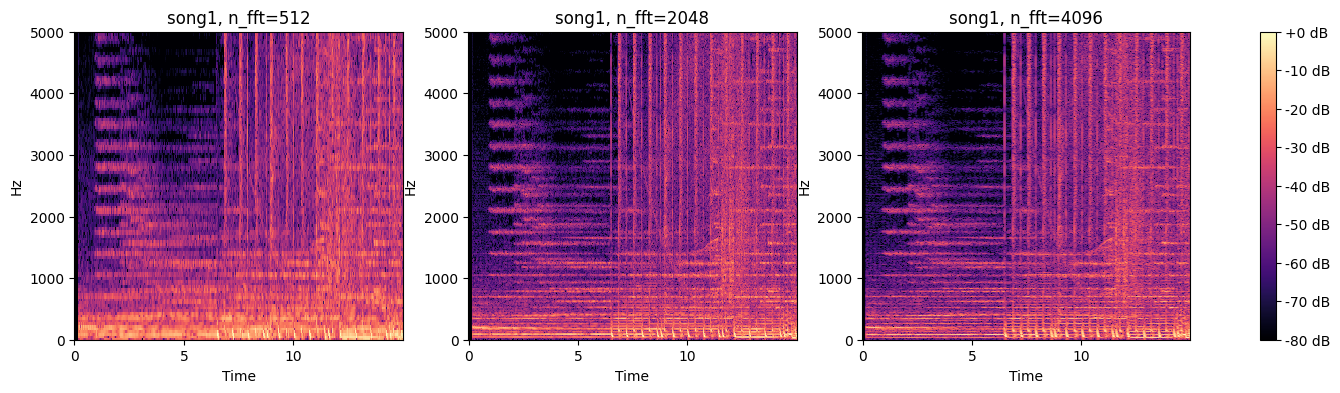

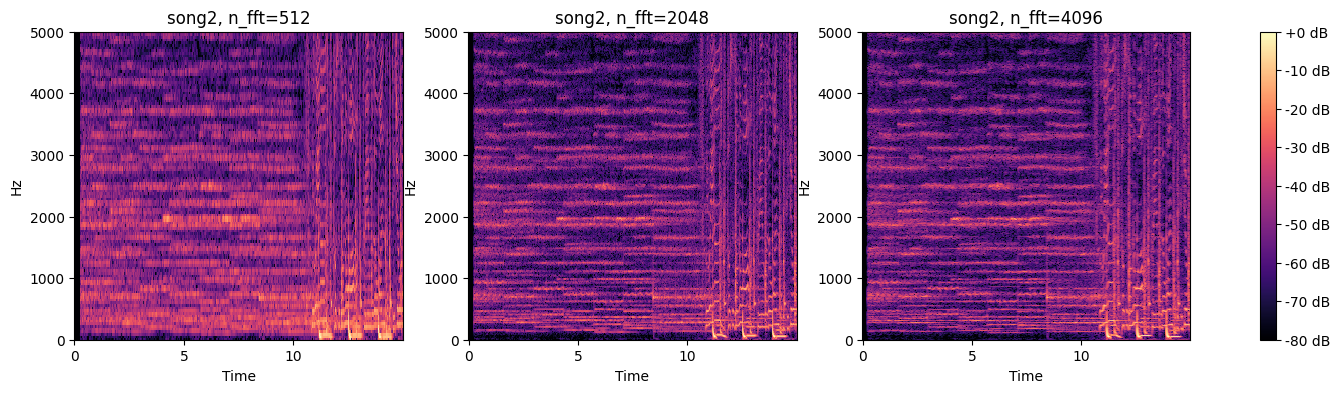

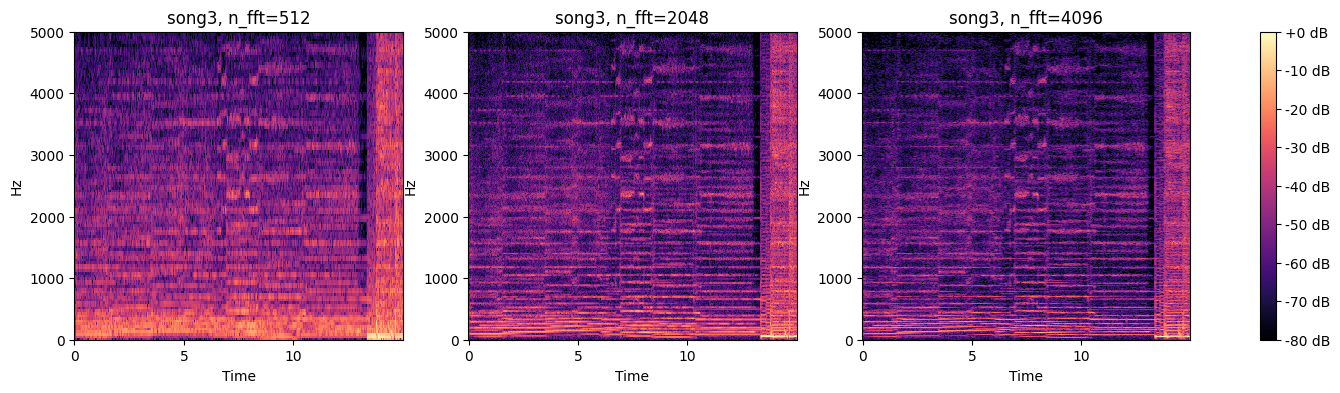


TRADE-OFF: A short window (512) gives sharp timing but blurry frequencies (~43 Hz bins),
so notes smear vertically. A long window (4096) separates close frequencies (~5 Hz)
but smears fast events in time (~186 ms). n_fft=2048, hop=512 (~93 ms window,
~10.8 Hz resolution, ~23 ms step) is a good compromise and is our recommended
configuration.


In [ ]:
def compute_spec(y, n_fft=N_FFT, hop=HOP):
    S = np.abs(librosa.stft(y, n_fft=n_fft, hop_length=hop))
    return librosa.amplitude_to_db(S, ref=np.max)

window_sizes = [512, 2048, 4096]
print("n_fft | freq resolution (Hz) | window length (ms)")
for n in window_sizes:
    print(f"{n:5d} | {SR/n:20.2f} | {1000*n/SR:.1f}")

for name, y in songs.items():
    fig, axes = plt.subplots(1, len(window_sizes), figsize=(18, 4))
    seg = y[:SR*15]
    for ax, n in zip(axes, window_sizes):
        S_db = compute_spec(seg, n_fft=n, hop=n // 4)
        img = librosa.display.specshow(S_db, sr=SR, hop_length=n // 4,
                                       x_axis="time", y_axis="hz", ax=ax)
        ax.set_ylim(0, 5000); ax.set_title(f"{name}, n_fft={n}")
    fig.colorbar(img, ax=axes, format="%+2.0f dB"); plt.show()

print("""
TRADE-OFF: A short window (512) gives sharp timing but blurry frequencies (~43 Hz bins),
so notes smear vertically. A long window (4096) separates close frequencies (~5 Hz)
but smears fast events in time (~186 ms). n_fft=2048, hop=512 (~93 ms window,
~10.8 Hz resolution, ~23 ms step) is a good compromise and is our recommended
configuration.""")

TASK 3

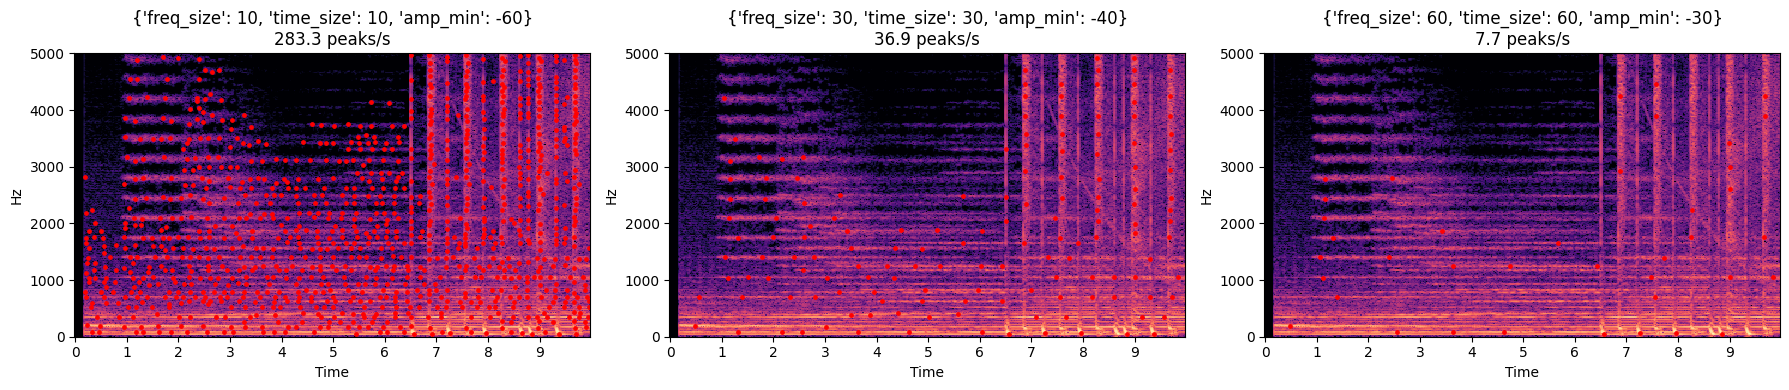

song1 peaks: 7179
song2 peaks: 4497
song3 peaks: 9365


In [ ]:
def get_peaks(S_db, freq_size=30, time_size=30, amp_min=-40):
    """Local maxima in a (freq_size x time_size) neighbourhood above amp_min dB.
    Returns array of (time_idx, freq_idx) sorted by time."""
    local_max = maximum_filter(S_db, size=(freq_size, time_size),
                               mode="constant", cval=S_db.min()) == S_db
    mask = local_max & (S_db > amp_min)
    f_idx, t_idx = np.nonzero(mask)
    order = np.lexsort((f_idx, t_idx))
    return np.stack([t_idx[order], f_idx[order]], axis=1)

# Experiment with thresholds and spacing on song1
S_demo = compute_spec(songs["song1"])
configs = [dict(freq_size=10, time_size=10, amp_min=-60),   # lots of clutter
           dict(freq_size=30, time_size=30, amp_min=-40),   # balanced
           dict(freq_size=60, time_size=60, amp_min=-30)]   # very sparse
n_show = int(10 * SR / HOP)   # first 10 s
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, cfg in zip(axes, configs):
    pk = get_peaks(S_demo, **cfg)
    librosa.display.specshow(S_demo[:, :n_show], sr=SR, hop_length=HOP,
                             x_axis="time", y_axis="hz", ax=ax)
    sel = pk[pk[:, 0] < n_show]
    ax.scatter(sel[:, 0] * HOP / SR, sel[:, 1] * SR / N_FFT, s=6, c="red")
    ax.set_ylim(0, 5000)
    ax.set_title(f"{cfg}\n{len(pk)/(S_demo.shape[1]*HOP/SR):.1f} peaks/s")
plt.tight_layout(); plt.show()

# Chosen settings, used for the rest of the project
PEAK_PARAMS = dict(freq_size=30, time_size=30, amp_min=-40)
SPECS = {n: compute_spec(y) for n, y in songs.items()}
PEAKS = {n: get_peaks(S, **PEAK_PARAMS) for n, S in SPECS.items()}
for n, p in PEAKS.items():
    print(n, "peaks:", len(p))

TASK 1,2 and 3 done by :  

Krish Tayal, Vijya, Shaurya

TASK 4

song1: 71556 fingerprints


,f1_bin,f2_bin,dt_frames,t_anchor_frame
0,18,65,3,21
1,18,130,25,21
2,18,97,27,21
3,18,194,28,21
4,18,8,36,21


song2: 43574 fingerprints


,f1_bin,f2_bin,dt_frames,t_anchor_frame
0,138,290,1,16
1,138,174,5,16
2,138,29,11,16
3,138,68,15,16
4,138,116,17,16


song3: 93024 fingerprints


,f1_bin,f2_bin,dt_frames,t_anchor_frame
0,91,109,1,3
1,91,128,1,3
2,91,165,3,3
3,91,146,10,3
4,91,218,10,3


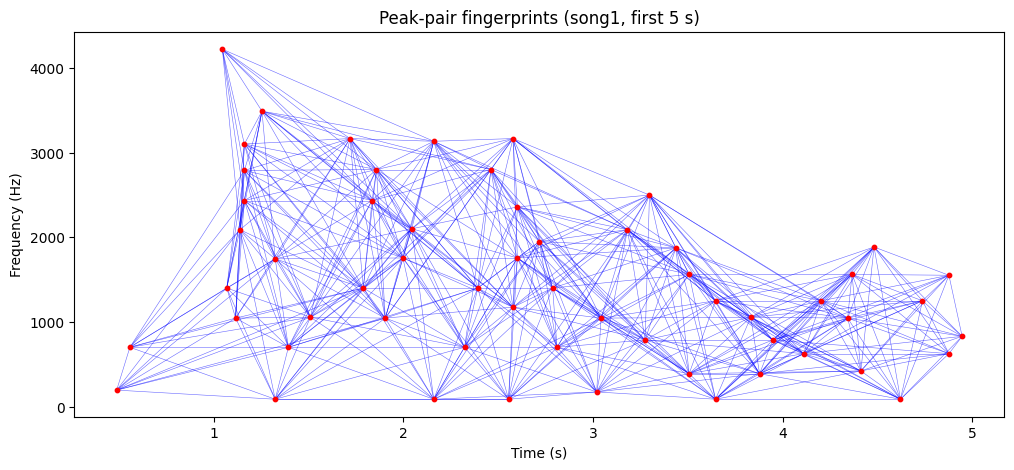

In [ ]:
PAIR_PARAMS = dict(fan_out=10, min_dt=1, max_dt=100, max_df=200)

def make_pairs(peaks, fan_out=10, min_dt=1, max_dt=100, max_df=200):
    """Each anchor peak is paired with up to fan_out later peaks in a target zone.
    Returns list of (f1, f2, dt, t1) in bin/frame units."""
    pairs, n = [], len(peaks)
    for i in range(n):
        t1, f1 = peaks[i]
        count = 0
        for j in range(i + 1, n):
            t2, f2 = peaks[j]
            dt = t2 - t1
            if dt > max_dt: break
            if dt < min_dt or abs(f2 - f1) > max_df: continue
            pairs.append((int(f1), int(f2), int(dt), int(t1)))
            count += 1
            if count >= fan_out: break
    return pairs

FPS = {n: make_pairs(p, **PAIR_PARAMS) for n, p in PEAKS.items()}
for n, f in FPS.items():
    print(f"{n}: {len(f)} fingerprints")
    display(pd.DataFrame(f[:5], columns=["f1_bin", "f2_bin", "dt_frames", "t_anchor_frame"]))

# Visualise candidate fingerprints on first 5 s of song1
n_show = int(5 * SR / HOP)
pk = PEAKS["song1"]; pk5 = pk[pk[:, 0] < n_show]
pairs5 = [p for p in FPS["song1"] if p[3] < n_show and p[3] + p[2] < n_show]
plt.figure(figsize=(12, 5))
plt.scatter(pk5[:, 0] * HOP / SR, pk5[:, 1] * SR / N_FFT, s=10, c="red", zorder=3)
for f1, f2, dt, t1 in pairs5:
    plt.plot([t1 * HOP / SR, (t1 + dt) * HOP / SR],
             [f1 * SR / N_FFT, f2 * SR / N_FFT], linewidth=0.4, c="blue", alpha=0.6)
plt.xlabel("Time (s)"); plt.ylabel("Frequency (Hz)")
plt.title("Peak-pair fingerprints (song1, first 5 s)"); plt.show()

TASK 5

In [ ]:
def baseline_feature(y):
    """Average log-mel spectrum (64 bands), level removed."""
    M = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=N_FFT, hop_length=HOP, n_mels=64)
    v = librosa.power_to_db(M, ref=1.0).mean(axis=1)
    return v - v.mean()

DB_FEATS = {n: baseline_feature(y) for n, y in songs.items()}
DB_MEAN = np.mean(list(DB_FEATS.values()), axis=0)

def cosine(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-9))

def recognise_baseline(yq):
    v = baseline_feature(yq) - DB_MEAN
    scores = {n: cosine(v, f - DB_MEAN) for n, f in DB_FEATS.items()}
    best = max(scores, key=scores.get)
    return best, scores[best], scores

def make_query(y, start_s, dur_s):
    a = int(start_s * SR)
    return y[a:a + int(dur_s * SR)]

for name, y in songs.items():
    q = make_query(y, start_s=20, dur_s=10)
    best, score, all_scores = recognise_baseline(q)
    print(f"True: {name} -> Predicted: {best} (similarity {score:.3f})",
          {k: round(v, 3) for k, v in all_scores.items()})

True: song1 -> Predicted: song1 (similarity 0.859) {'song1': 0.859, 'song2': -0.648, 'song3': -0.132}
True: song2 -> Predicted: song2 (similarity 0.571) {'song1': -0.389, 'song2': 0.571, 'song3': -0.396}
True: song3 -> Predicted: song1 (similarity 0.536) {'song1': 0.536, 'song2': -0.732, 'song3': 0.454}


TASK 6


Unique hashes in index: 166419
True: song1 -> Predicted: song1 (top offset votes: 964)
True: song2 -> Predicted: song2 (top offset votes: 576)
True: song3 -> Predicted: song3 (top offset votes: 1311)


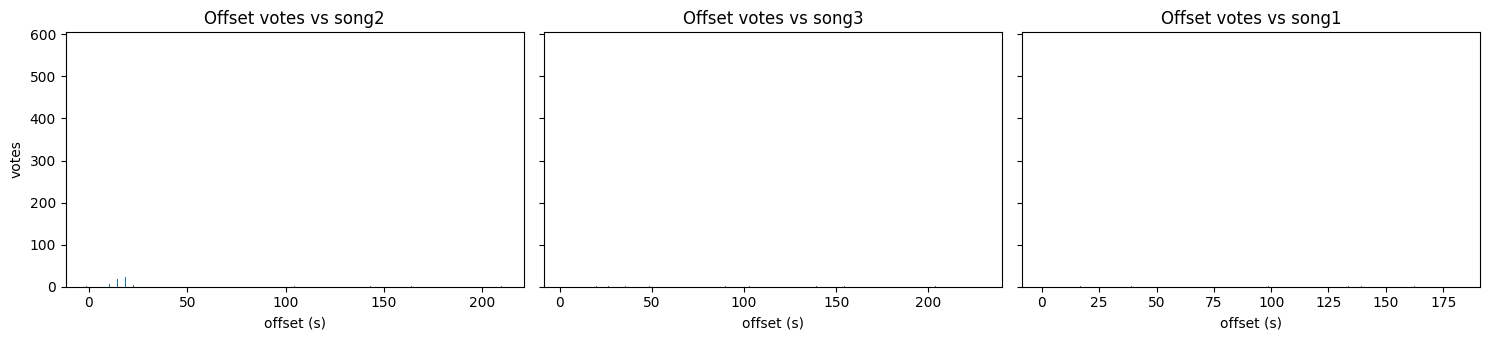

In [ ]:
def hash_key(f1, f2, dt):
    return (f1 // 2, f2 // 2, dt)

INDEX = defaultdict(list)
for name, pairs in FPS.items():
    for f1, f2, dt, t1 in pairs:
        INDEX[hash_key(f1, f2, dt)].append((name, t1))
print("Unique hashes in index:", len(INDEX))

def fingerprint_signal(y):
    S_db = compute_spec(y)
    return make_pairs(get_peaks(S_db, **PEAK_PARAMS), **PAIR_PARAMS)

def recognise_fingerprint(yq):
    """Returns (best_song, vote_count, votes) where votes[song] = Counter(offset->count)."""
    votes = defaultdict(Counter)
    for f1, f2, dt, tq in fingerprint_signal(yq):
        for name, tdb in INDEX.get(hash_key(f1, f2, dt), []):
            votes[name][tdb - tq] += 1
    if not votes:
        return None, 0, votes
    scores = {n: max(c.values()) for n, c in votes.items()}
    best = max(scores, key=scores.get)
    return best, scores[best], votes

# Test
for name, y in songs.items():
    q = make_query(y, start_s=20, dur_s=10)
    best, score, votes = recognise_fingerprint(q)
    print(f"True: {name} -> Predicted: {best} (top offset votes: {score})")

# Offset-voting histogram for one query
true = "song2"
q = make_query(songs[true], 20, 10)
best, score, votes = recognise_fingerprint(q)
fig, axes = plt.subplots(1, len(votes), figsize=(5 * len(votes), 3.5), sharey=True)
axes = np.atleast_1d(axes)
for ax, (n, c) in zip(axes, votes.items()):
    ax.bar([k * HOP / SR for k in c.keys()], list(c.values()), width=0.05)
    ax.set_title(f"Offset votes vs {n}"); ax.set_xlabel("offset (s)")
axes[0].set_ylabel("votes")
plt.tight_layout(); plt.show()

TASKs 4,5,6 done by :

Kumar Vaibhav, Yash Joshi, Shruti

TASK 8 to 10

In [ ]:
def evaluate(transform=None, dur=10, n_trials=4, start_fracs=None, seed=0):
    """Accuracy of both methods. Cuts queries from each song, optionally transforms them."""
    rng = np.random.default_rng(seed)
    ok_fp = ok_bl = total = 0
    for name, y in songs.items():
        max_start = len(y) / SR - dur
        if max_start <= 0:
            continue
        starts = (np.array(start_fracs) * max_start if start_fracs is not None
                  else rng.uniform(0, max_start, n_trials))
        for s in starts:
            q = make_query(y, s, dur)
            if transform is not None:
                q = transform(q)
            ok_fp += (recognise_fingerprint(q)[0] == name)
            ok_bl += (recognise_baseline(q)[0] == name)
            total += 1
    return {"fingerprint_acc": ok_fp / total, "baseline_acc": ok_bl / total, "n_queries": total}

TASK 8

,duration_s,fingerprint_acc,baseline_acc,n_queries
0,1,1.0,0.733333,15
1,2,1.0,0.733333,15
2,3,1.0,0.800000,15
3,5,1.0,0.800000,15
4,10,1.0,0.800000,15
5,15,1.0,0.866667,15


,start_fraction,fingerprint_acc,baseline_acc,n_queries
0,0.00,1.000000,0.0,3
1,0.25,1.000000,1.0,3
2,0.50,1.000000,1.0,3
3,0.75,1.000000,1.0,3
4,1.00,0.666667,1.0,3


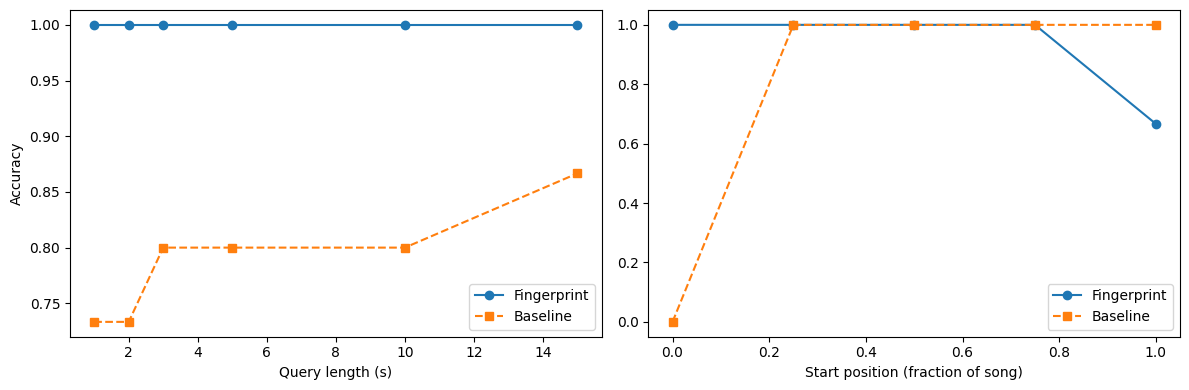

In [ ]:
# (a) Query duration
durations = [1, 2, 3, 5, 10, 15]
res = [{"duration_s": d, **evaluate(dur=d, n_trials=5)} for d in durations]
df_dur = pd.DataFrame(res); display(df_dur)

# (b) Starting position (10 s query, start at 0%, 25%, 50%, 75%, 100% of valid range)
fracs = [0, 0.25, 0.5, 0.75, 1.0]
res = [{"start_fraction": f, **evaluate(dur=10, start_fracs=[f])} for f in fracs]
df_start = pd.DataFrame(res); display(df_start)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(df_dur.duration_s, df_dur.fingerprint_acc, "o-", label="Fingerprint")
axes[0].plot(df_dur.duration_s, df_dur.baseline_acc, "s--", label="Baseline")
axes[0].set_xlabel("Query length (s)"); axes[0].set_ylabel("Accuracy"); axes[0].legend()
axes[1].plot(df_start.start_fraction, df_start.fingerprint_acc, "o-", label="Fingerprint")
axes[1].plot(df_start.start_fraction, df_start.baseline_acc, "s--", label="Baseline")
axes[1].set_xlabel("Start position (fraction of song)"); axes[1].legend()
plt.tight_layout(); plt.show()

TASK 9

,SNR_dB,fingerprint_acc,baseline_acc,n_queries
0,clean,1.0,0.750000,12
1,30,1.0,0.833333,12
2,20,1.0,0.750000,12
3,10,1.0,0.583333,12
4,5,1.0,0.583333,12
5,0,1.0,0.666667,12
6,-5,1.0,0.416667,12


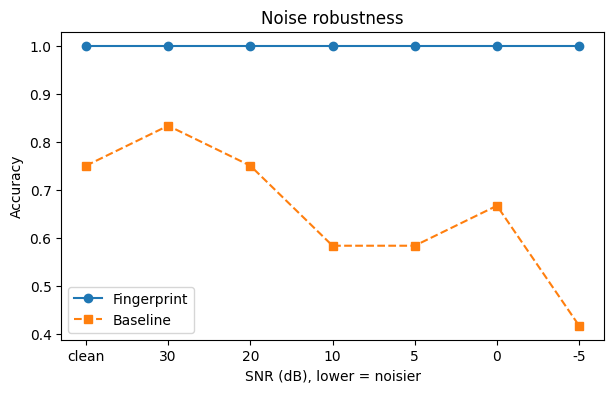

In [ ]:
def add_noise(y, snr_db, seed=0):
    rng = np.random.default_rng(seed)
    noise_power = np.mean(y ** 2) / (10 ** (snr_db / 10))
    return y + rng.normal(0, np.sqrt(noise_power), len(y))

snr_levels = [None, 30, 20, 10, 5, 0, -5]
res = []
for snr in snr_levels:
    tf = None if snr is None else (lambda q, s=snr: add_noise(q, s))
    res.append({"SNR_dB": "clean" if snr is None else snr, **evaluate(transform=tf, dur=10, n_trials=4)})
df_noise = pd.DataFrame(res); display(df_noise)

plt.figure(figsize=(7, 4))
x = range(len(df_noise))
plt.plot(x, df_noise.fingerprint_acc, "o-", label="Fingerprint")
plt.plot(x, df_noise.baseline_acc, "s--", label="Baseline")
plt.xticks(x, df_noise.SNR_dB); plt.xlabel("SNR (dB), lower = noisier")
plt.ylabel("Accuracy"); plt.legend(); plt.title("Noise robustness"); plt.show()

TASK 10

,transformation,fingerprint_acc,baseline_acc,n_queries
0,none,1.000000,0.777778,9
1,pitch -2 semitones,0.666667,0.555556,9
2,pitch -1 semitones,0.555556,0.444444,9
3,pitch +1 semitones,0.666667,0.666667,9
4,pitch +2 semitones,0.777778,0.777778,9
5,time-stretch x0.9,1.000000,0.777778,9
6,time-stretch x0.95,1.000000,0.777778,9
7,time-stretch x1.05,1.000000,0.777778,9
8,time-stretch x1.1,1.000000,0.777778,9


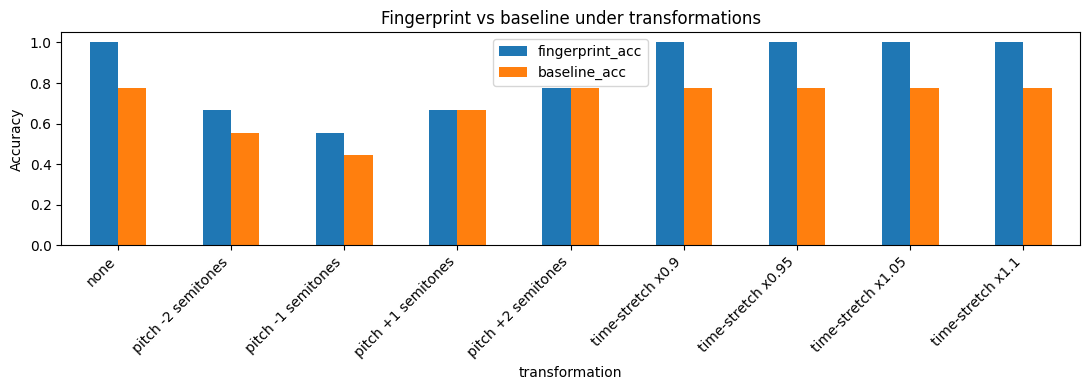

In [ ]:
def pitch(n_steps):
    return lambda q: librosa.effects.pitch_shift(q, sr=SR, n_steps=n_steps)

def stretch(rate):
    return lambda q: librosa.effects.time_stretch(q, rate=rate)

tests = [("none", None)]
tests += [(f"pitch {n:+d} semitones", pitch(n)) for n in [-2, -1, 1, 2]]
tests += [(f"time-stretch x{r}", stretch(r)) for r in [0.9, 0.95, 1.05, 1.1]]

res = []
for label, tf in tests:
    r = evaluate(transform=tf, dur=10, n_trials=3)
    res.append({"transformation": label, **r})
df_tf = pd.DataFrame(res); display(df_tf)

df_tf.set_index("transformation")[["fingerprint_acc", "baseline_acc"]].plot(
    kind="bar", figsize=(11, 4), ylim=(0, 1.05))
plt.ylabel("Accuracy"); plt.title("Fingerprint vs baseline under transformations")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

TASKs 8,9,10 done by :